<a href="https://colab.research.google.com/github/Fa-224/Image-Processing-Project/blob/main/Planty_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Planty — Image Preprocessing

**Purpose:** Explore and test suitable image preprocessing techniques for plant disease classification.

**Dataset:** PlantVillage

**Current Stage:** Color Processing


Using Colab cache for faster access to the 'plantdisease' dataset.


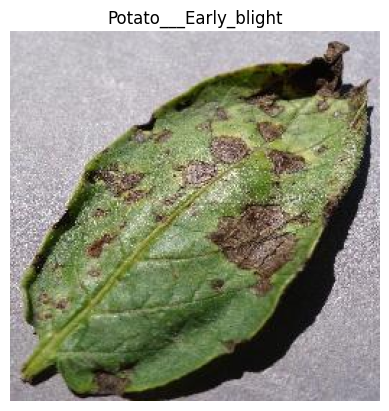

Image size: (256, 256)
Color mode: RGB


In [2]:
# Load and inspect a sample image
import os
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub

# Load the dataset
dataset_path = kagglehub.dataset_download("emmarex/plantdisease")
folder_path = os.path.join(dataset_path, "PlantVillage")

# Select a sample image
class_name = "Potato___Early_blight"
class_path = os.path.join(folder_path, class_name)
image_name = next(
   f for f in os.listdir(class_path)
   if f.lower().endswith((".jpg", ".jpeg", ".png"))
)
image_path = os.path.join(class_path, image_name)
image = Image.open(image_path).convert("RGB")

# Display the image
plt.imshow(image)
plt.title(class_name)
plt.axis("off")
plt.show()
print("Image size:", image.size)
print("Color mode:", image.mode)

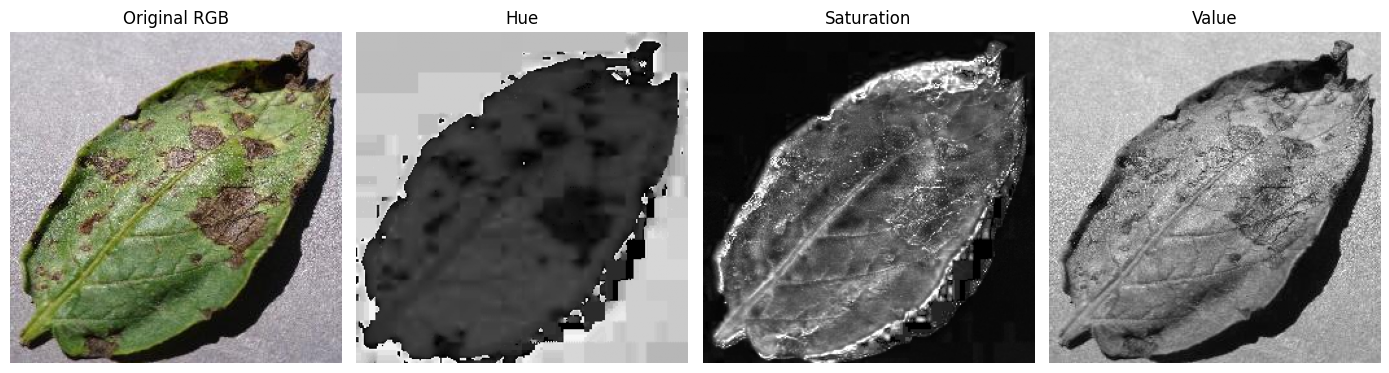

In [3]:
# Convert RGB to HSV
import numpy as np
import matplotlib.pyplot as plt
from skimage.color import rgb2hsv
image_array = np.array(image) / 255.0
hsv_image = rgb2hsv(image_array)

# Display HSV channels
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(image)
axes[0].set_title("Original RGB")
axes[1].imshow(hsv_image[:, :, 0], cmap="gray")
axes[1].set_title("Hue")
axes[2].imshow(hsv_image[:, :, 1], cmap="gray")
axes[2].set_title("Saturation")
axes[3].imshow(hsv_image[:, :, 2], cmap="gray")
axes[3].set_title("Value")
for ax in axes:
   ax.axis("off")
plt.tight_layout()
plt.show()

## Dataset Preparation
- Training Set: 70%
- Validation Set: 15%
- Testing Set: 15%
Invalid images will be excluded before splitting the dataset.
The same data split will be used to compare RGB and HSV fairly.